# Solar Radiation Prediction Using Meteorological Data

**Exploratory Data Analysis, Preprocessing, Visualization, and Machine Learning-Based Forecasting**

**Author:** Rasaq Oluwasegun DAMISA  
**Programme:** MSc Sustainable Energy Future  
**Institution:** ECE — École d'Ingénieurs  
**Course:** Big Data and Energy Data Analysis  
**Academic Year:** 2026–2027

---

**Dataset:** Solar Radiation Prediction (NASA HI-SEAS Weather Station, Hawaii)

**Project Scope:** Data inspection, preprocessing, exploratory data analysis, solar resource assessment, and comparative forecasting using statistical, machine learning, and deep learning models.

## 1. Introduction and Project Objectives

### 1.1 Background and Context

Solar radiation is a fundamental renewable energy resource that determines the amount of solar energy available for conversion into electricity through photovoltaic (PV) systems. However, its availability varies with time of day, atmospheric conditions, and local weather patterns.

Understanding these variations is important for solar resource assessment, PV system planning, and short-term energy forecasting.

This project investigates solar radiation measurements collected at the NASA HI-SEAS weather station in Hawaii. It applies exploratory data analysis, preprocessing, and visualization techniques to examine radiation patterns and their relationships with meteorological conditions.

The project also explores the potential of statistical, machine learning, and deep learning approaches for predicting solar radiation.

### 1.2 Project Objectives

The objectives of this project are to:

1. Examine the structure, quality, and statistical characteristics of the solar radiation dataset.
2. Identify and address data quality issues, including missing values, outliers, and temporal inconsistencies.
3. Analyze solar radiation variability and its relationships with meteorological variables.
4. Visualize temporal patterns, distributions, and correlations relevant to solar energy resource assessment.
5. Develop and compare forecasting models using consistent evaluation metrics.
6. Interpret the findings in the context of renewable energy forecasting and operational planning.

### 1.3 Research Question

To what extent can historical meteorological conditions and temporal patterns explain and predict solar radiation variability, and how can these insights support solar energy resource assessment?

### 1.4 Scope of the Study

The study focuses on solar radiation and associated meteorological observations from the HI-SEAS weather station in Hawaii.

The analysis covers data inspection, preprocessing, exploratory visualization, and short-term forecasting. Solar radiation is treated as the primary target variable, while meteorological and temporal measurements serve as potential explanatory or predictive features.

The project evaluates solar resource availability rather than actual PV electricity production, since the dataset does not directly measure electricity generated by solar panels.

## 2. Dataset Description, Loading, and Initial Inspection

### 2.1 Dataset Description

The dataset used in this study is the **Solar Radiation Prediction dataset**, obtained from Kaggle and associated with the NASA HI-SEAS weather station in Hawaii.

It contains solar radiation measurements and meteorological observations, including temperature, atmospheric pressure, humidity, wind speed, wind direction, and time-related information.

Solar radiation, measured in watts per square metre (W/m²), is the primary variable of interest.

**Dataset source:** [Solar Energy — Kaggle](https://www.kaggle.com/datasets/dronio/SolarEnergy)

### 2.2 Python Libraries and Dataset Loading

The following libraries are used for data manipulation, numerical analysis, visualization, and machine learning. Additional deep learning libraries will be imported when the forecasting stage begins.

In [1]:

# Core libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display and visualization settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid")

# Load the original solar radiation dataset
data_path = "../data/Solar_Radiation_Prediction.csv"
df = pd.read_csv(data_path)

# Confirm successful loading
print("Dataset loaded successfully!")
print(f"Number of observations: {df.shape[0]:,}")
print(f"Number of variables: {df.shape[1]}")


Dataset loaded successfully!
Number of observations: 32,686
Number of variables: 11


### 2.3 Dataset Structure and Initial Inspection

An initial inspection is performed to understand the dataset's organization, identify the available variables, examine their data types, and verify how observations are recorded.

The inspection includes a preview of the first five records and a summary of the DataFrame structure. These findings will guide subsequent preprocessing and feature engineering decisions.

In [2]:

# Preview the first five observations
display(df.head())

# Inspect column names, data types, and non-null counts
df.info()


,UNIXTime,Data,Time,Radiation,Temperature,Pressure,Humidity,WindDirection(Degrees),Speed,TimeSunRise,TimeSunSet
0,1475229326,9/29/2016 12:00:00 AM,23:55:26,1.21,48,30.46,59,177.39,5.62,06:13:00,18:13:00
1,1475229023,9/29/2016 12:00:00 AM,23:50:23,1.21,48,30.46,58,176.78,3.37,06:13:00,18:13:00
2,1475228726,9/29/2016 12:00:00 AM,23:45:26,1.23,48,30.46,57,158.75,3.37,06:13:00,18:13:00
3,1475228421,9/29/2016 12:00:00 AM,23:40:21,1.21,48,30.46,60,137.71,3.37,06:13:00,18:13:00
4,1475228124,9/29/2016 12:00:00 AM,23:35:24,1.17,48,30.46,62,104.95,5.62,06:13:00,18:13:00


<class 'pandas.DataFrame'>
RangeIndex: 32686 entries, 0 to 32685
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   UNIXTime                32686 non-null  int64  
 1   Data                    32686 non-null  str    
 2   Time                    32686 non-null  str    
 3   Radiation               32686 non-null  float64
 4   Temperature             32686 non-null  int64  
 5   Pressure                32686 non-null  float64
 6   Humidity                32686 non-null  int64  
 7   WindDirection(Degrees)  32686 non-null  float64
 8   Speed                   32686 non-null  float64
 9   TimeSunRise             32686 non-null  str    
 10  TimeSunSet              32686 non-null  str    
dtypes: float64(4), int64(3), str(4)
memory usage: 4.2 MB


### 2.3.1 Interpretation of Dataset Structure

The initial inspection confirms that the dataset contains 32,686 observations distributed across 11 variables. These include solar radiation measurements, meteorological parameters, and temporal information.

Seven variables are numerical, while four are stored as strings. All columns contain 32,686 non-null entries, indicating that no missing values are immediately apparent. However, further validation is required to identify potential invalid measurements, duplicate records, and temporal inconsistencies.

The `Radiation` variable represents the prediction target, while temperature, pressure, humidity, wind speed, and wind direction provide potential explanatory features.

The timestamp variables require preprocessing to support chronological analysis. The initial observations also suggest that the records are arranged in reverse chronological order.

These findings establish the basis for subsequent data quality assessment, temporal preprocessing, and exploratory analysis.

### 2.4 Descriptive Statistical Analysis

Descriptive statistics are used to examine the central tendency, variability, and range of the numerical variables.

The analysis considers the mean, standard deviation, minimum, maximum, and quartile values. These measures provide an initial understanding of solar radiation variability and meteorological conditions while helping identify potential extreme observations requiring further investigation.

In [3]:

# Descriptive statistics for physical measurements
measurement_cols = [
    "Radiation",
    "Temperature",
    "Pressure",
    "Humidity",
    "WindDirection(Degrees)",
    "Speed"
]

# Display summary statistics
display(df[measurement_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
Radiation,32686.00,207.12,315.92,1.11,1.23,2.66,354.24,1601.26
Temperature,32686.00,51.10,6.20,34.00,46.00,50.00,55.00,71.00
Pressure,32686.00,30.42,0.05,30.19,30.40,30.43,30.46,30.56
Humidity,32686.00,75.02,25.99,8.00,56.00,85.00,97.00,103.00
WindDirection(Degrees),32686.00,143.49,83.17,0.09,82.23,147.70,179.31,359.95
Speed,32686.00,6.24,3.49,0.00,3.37,5.62,7.87,40.50


### 2.4.1 Interpretation of Descriptive Statistics

The descriptive statistics reveal substantial variability in solar radiation and meteorological conditions across the 32,686 observations.

**Solar Radiation:** The mean radiation is 207.12 W/m², with a standard deviation of 315.92 W/m². The median of 2.66 W/m² is considerably lower than the mean, indicating a strongly right-skewed distribution. This suggests that low-radiation observations occur frequently, while periods of higher radiation increase the overall average.

**Temperature and Atmospheric Pressure:** Temperature ranges from 34°F to 71°F, with a mean of 51.10°F. Atmospheric pressure exhibits comparatively limited variability, ranging from 30.19 to 30.56 inHg.

**Humidity:** The mean relative humidity is 75.02%, indicating generally humid conditions. However, the maximum recorded value of 103% exceeds the conventional physical range and requires further investigation during preprocessing.

**Wind Conditions:** Wind direction spans almost the full 0°–360° range, while wind speed varies between 0 and 40.50 mph. Wind direction is a circular variable, so its arithmetic mean should be interpreted cautiously.

**Implications for Solar Energy Analysis:** The substantial difference between mean and median radiation highlights the importance of distinguishing daytime and nighttime observations. Additionally, unusually high radiation and humidity measurements require quality assessment before developing forecasting models.

Overall, the statistical findings provide an initial understanding of the dataset and establish priorities for subsequent data cleaning and exploratory analysis.

## 3. Data Cleaning and Preprocessing

Data preprocessing is essential for ensuring the reliability of exploratory analysis and forecasting results. This section evaluates data completeness, duplicate observations, timestamp consistency, physically implausible measurements, and the need for feature transformations or temporal resampling.

The original dataset will be preserved, while a separate working DataFrame will be used for cleaning and subsequent analysis.

### 3.1 Missing Values and Duplicate Records

The first preprocessing stage examines missing observations and duplicate records. Identifying these issues helps prevent biased statistical summaries and unnecessary duplication during model training.

In [4]:

# Create a working copy while preserving the original dataset
df_clean = df.copy()

# Assess missing values and duplicate records
missing_counts = df_clean.isna().sum()
duplicate_rows = df_clean.duplicated().sum()
duplicate_timestamps = df_clean["UNIXTime"].duplicated().sum()

# Summarize data quality
quality_summary = pd.DataFrame({
    "Metric": [
        "Total observations",
        "Missing values",
        "Duplicate rows",
        "Duplicate timestamps"
    ],
    "Count": [
        len(df_clean),
        missing_counts.sum(),
        duplicate_rows,
        duplicate_timestamps
    ]
})

display(quality_summary)

# Show missing values by column only if any exist
if missing_counts.sum() > 0:
    display(missing_counts[missing_counts > 0].to_frame("Missing Count"))


,Metric,Count
0,Total observations,32686
1,Missing values,0
2,Duplicate rows,0
3,Duplicate timestamps,0


### 3.1.1 Interpretation of Data Quality Assessment

The initial data-quality assessment confirms that all 32,686 observations are complete, with no missing values, duplicate rows, or duplicate UNIX timestamps.

Consequently, no missing-value imputation or duplicate removal is required at this stage. Preserving all observations avoids unnecessary modification of the original dataset.

Nevertheless, the absence of missing values and duplicates does not guarantee complete data reliability. Further preprocessing is necessary to verify chronological consistency, identify irregular measurement intervals, and investigate physically implausible meteorological observations.

### 3.2 Timestamp Conversion and Chronological Ordering

The dataset contains UNIX timestamps alongside separate date and time fields. To establish a consistent temporal structure, UNIX timestamps are converted into timezone-aware datetime values.

The resulting timestamps are converted to Hawaii Standard Time (HST), corresponding to the location of the HI-SEAS weather station.

Observations are then arranged chronologically to support time-series visualization, temporal feature engineering, and forecasting. Measurement intervals are also examined to identify irregular sampling or potential gaps in the recorded observations.

In [5]:

# Convert UNIX timestamps to Hawaii local time
df_clean["Datetime"] = (
    pd.to_datetime(df_clean["UNIXTime"], unit="s", utc=True)
    .dt.tz_convert("Pacific/Honolulu")
)

# Sort observations chronologically
df_clean = df_clean.sort_values("Datetime").reset_index(drop=True)

# Calculate intervals between consecutive measurements
time_intervals = df_clean["Datetime"].diff().dropna()

# Summarize temporal coverage and sampling intervals
temporal_summary = pd.DataFrame({
    "Metric": [
        "First observation",
        "Last observation",
        "Total observations",
        "Median sampling interval",
        "Minimum sampling interval",
        "Maximum sampling interval",
        "Unique sampling intervals"
    ],
    "Value": [
        str(df_clean["Datetime"].min()),
        str(df_clean["Datetime"].max()),
        len(df_clean),
        str(time_intervals.median()),
        str(time_intervals.min()),
        str(time_intervals.max()),
        time_intervals.nunique()
    ]
})

display(temporal_summary)

# Show the most common measurement intervals
display(
    time_intervals.value_counts()
    .head(10)
    .rename_axis("Sampling Interval")
    .reset_index(name="Frequency")
)


,Metric,Value
0,First observation,2016-09-01 00:00:08-10:00
1,Last observation,2016-12-31 23:55:01-10:00
2,Total observations,32686
3,Median sampling interval,0 days 00:05:00
4,Minimum sampling interval,0 days 00:00:01
5,Maximum sampling interval,2 days 14:24:49
6,Unique sampling intervals,184


,Sampling Interval,Frequency
0,0 days 00:05:00,6326
1,0 days 00:04:59,4317
2,0 days 00:05:01,4262
3,0 days 00:04:58,2675
4,0 days 00:05:02,2634
5,0 days 00:04:57,2112
6,0 days 00:05:03,2085
7,0 days 00:04:56,1094
8,0 days 00:05:04,1077
9,0 days 00:05:05,633


### 3.2.1 Interpretation of Temporal Structure

The timestamp analysis establishes that the dataset covers September 1 to December 31, 2016, representing approximately four months of solar radiation observations.

The median sampling interval is five minutes, indicating that measurements were generally recorded at approximately five-minute intervals. However, 184 distinct sampling intervals were identified, demonstrating that the time series is not perfectly regular.

Small variations of a few seconds around the five-minute interval suggest minor timestamp irregularities. More importantly, the maximum interval of approximately 2 days and 14 hours indicates a substantial gap in the observations.

These findings highlight the need for appropriate temporal resampling and gap handling before time-series forecasting. Establishing a consistent temporal frequency will be particularly important for constructing historical input sequences for RNN and LSTM models.

The chronological ordering and conversion to Hawaii Standard Time provide a reliable temporal reference for subsequent solar radiation analysis.

### 3.3 Outlier Detection and Treatment

Outlier detection is performed to identify unusually high or low meteorological measurements that may affect statistical analysis and forecasting performance.

The Interquartile Range (IQR) method is applied to identify statistical outliers, while physical plausibility checks are used to assess potentially invalid measurements.

Statistical outliers are not automatically removed because extreme solar radiation and weather conditions may represent genuine environmental variability. Treatment decisions will therefore consider both the statistical results and the physical characteristics of each variable.

In [6]:

# Identify statistical outliers using the IQR method
Q1 = df_clean[measurement_cols].quantile(0.25)
Q3 = df_clean[measurement_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bounds = Q1 - 1.5 * IQR
upper_bounds = Q3 + 1.5 * IQR

# Count outliers for each numerical measurement
outlier_counts = (
    (df_clean[measurement_cols] < lower_bounds) |
    (df_clean[measurement_cols] > upper_bounds)
).sum()

outlier_summary = pd.DataFrame({
    "Outlier Count": outlier_counts,
    "Outlier Percentage (%)": (
        outlier_counts / len(df_clean) * 100
    ).round(2),
    "Lower IQR Bound": lower_bounds.round(2),
    "Upper IQR Bound": upper_bounds.round(2)
})

display(outlier_summary)

# Check physically questionable measurements
physical_checks = pd.DataFrame({
    "Condition": [
        "Negative solar radiation",
        "Humidity outside 0–100%",
        "Negative wind speed",
        "Wind direction outside 0–360°",
        "Non-positive atmospheric pressure"
    ],
    "Count": [
        (df_clean["Radiation"] < 0).sum(),
        ((df_clean["Humidity"] < 0) |
         (df_clean["Humidity"] > 100)).sum(),
        (df_clean["Speed"] < 0).sum(),
        ((df_clean["WindDirection(Degrees)"] < 0) |
         (df_clean["WindDirection(Degrees)"] > 360)).sum(),
        (df_clean["Pressure"] <= 0).sum()
    ]
})

display(physical_checks)


,Outlier Count,Outlier Percentage (%),Lower IQR Bound,Upper IQR Bound
Radiation,1965,6.01,-528.28,883.74
Temperature,89,0.27,32.50,68.50
Pressure,1662,5.08,30.31,30.55
Humidity,0,0.00,-5.50,158.50
WindDirection(Degrees),1618,4.95,-63.40,324.93
Speed,479,1.47,-3.38,14.62


,Condition,Count
0,Negative solar radiation,0
1,Humidity outside 0–100%,4311
2,Negative wind speed,0
3,Wind direction outside 0–360°,0
4,Non-positive atmospheric pressure,0


### 3.3.1 Interpretation of Outlier Detection

The IQR analysis identified statistical outliers across several meteorological variables. Solar radiation recorded 1,965 outliers (6.01%), followed by atmospheric pressure with 1,662 (5.08%), wind direction with 1,618 (4.95%), wind speed with 479 (1.47%), and temperature with 89 (0.27%).

These observations are not automatically classified as erroneous because extreme weather conditions and high solar radiation values may represent genuine environmental variability. Furthermore, the conventional IQR method has limitations when applied to strongly skewed radiation measurements and circular wind-direction data.

The physical plausibility assessment identified 4,311 humidity observations (13.19%) outside the conventional 0–100% relative humidity range. No negative solar radiation, negative wind speed, invalid wind direction, or non-positive atmospheric pressure measurements were detected.

The findings indicate that humidity requires targeted investigation before treatment. Other statistically unusual measurements will be retained unless additional evidence indicates measurement errors.

This approach prioritizes data integrity while avoiding unnecessary removal of potentially valid environmental observations.

In [7]:

# Investigate humidity observations exceeding 100%
invalid_humidity = df_clean.loc[
    df_clean["Humidity"] > 100,
    "Humidity"
]

# Examine the distribution of invalid humidity values
humidity_investigation = pd.DataFrame({
    "Metric": [
        "Invalid observations",
        "Percentage of dataset (%)",
        "Minimum invalid humidity (%)",
        "Maximum invalid humidity (%)",
        "Mean invalid humidity (%)"
    ],
    "Value": [
        len(invalid_humidity),
        round(len(invalid_humidity) / len(df_clean) * 100, 2),
        invalid_humidity.min(),
        invalid_humidity.max(),
        round(invalid_humidity.mean(), 2)
    ]
})

display(humidity_investigation)

# Frequency of humidity values exceeding 100%
display(
    invalid_humidity.value_counts()
    .sort_index()
    .rename_axis("Humidity (%)")
    .reset_index(name="Frequency")
)


,Metric,Value
0,Invalid observations,4311.00
1,Percentage of dataset (%),13.19
2,Minimum invalid humidity (%),101.00
3,Maximum invalid humidity (%),103.00
4,Mean invalid humidity (%),101.58


,Humidity (%),Frequency
0,101,2003
1,102,2107
2,103,201


### 3.3.2 Humidity Investigation and Treatment

Further investigation identified 4,311 relative humidity observations exceeding 100%, representing 13.19% of the dataset. These observations consist of 2,003 measurements at 101%, 2,107 at 102%, and 201 at 103%.

The limited exceedance range suggests a possible systematic measurement or calibration issue, although the underlying cause cannot be established from the available dataset.

To maintain physical consistency while preserving the temporal structure and other meteorological measurements, relative humidity values exceeding 100% are capped at 100%.

This treatment is adopted as a pragmatic preprocessing assumption. The original dataset remains unchanged, and the potential influence of humidity correction should be acknowledged when interpreting forecasting results.

Other statistical outliers are retained because there is insufficient evidence to classify them as erroneous measurements.

In [8]:

# Preserve original humidity measurements for traceability
df_clean["Humidity_Original"] = df_clean["Humidity"]

# Cap relative humidity at the conventional physical limit
df_clean["Humidity"] = df_clean["Humidity"].clip(upper=100)

# Verify the correction
humidity_correction = pd.DataFrame({
    "Metric": [
        "Observations corrected",
        "Maximum original humidity (%)",
        "Maximum corrected humidity (%)",
        "Remaining humidity values above 100%",
        "Total observations retained"
    ],
    "Value": [
        (df_clean["Humidity_Original"] > 100).sum(),
        df_clean["Humidity_Original"].max(),
        df_clean["Humidity"].max(),
        (df_clean["Humidity"] > 100).sum(),
        len(df_clean)
    ]
})

display(humidity_correction)


,Metric,Value
0,Observations corrected,4311
1,Maximum original humidity (%),103
2,Maximum corrected humidity (%),100
3,Remaining humidity values above 100%,0
4,Total observations retained,32686


### 3.4 Temporal Resampling and Missing Interval Management

The timestamp analysis revealed a median sampling interval of five minutes, with minor second-level variations and occasional substantial gaps.

To establish a consistent temporal structure, the cleaned measurements are aggregated into five-minute intervals. The mean is used for solar radiation and scalar meteorological variables, while wind direction is aggregated using a circular mean.

Intervals without observations are initially retained as missing rather than automatically interpolated. This prevents the creation of artificial solar radiation measurements across extended periods of missing data.

The resulting time series will support temporal visualization, feature engineering, and the development of forecasting models.

In [9]:

# Resample cleaned observations into regular 5-minute intervals
# Wind direction requires circular averaging rather than arithmetic averaging

def circular_mean_degrees(values):
    angles = np.deg2rad(values.dropna().to_numpy())

    if len(angles) == 0:
        return np.nan

    mean_sin = np.sin(angles).mean()
    mean_cos = np.cos(angles).mean()

    if np.hypot(mean_sin, mean_cos) < 1e-10:
        return np.nan

    return np.rad2deg(np.arctan2(mean_sin, mean_cos)) % 360


aggregation_rules = {
    col: "mean"
    for col in measurement_cols
    if col != "WindDirection(Degrees)"
}
aggregation_rules["WindDirection(Degrees)"] = circular_mean_degrees

df_resampled = (
    df_clean
    .set_index("Datetime")
    .resample("5min")
    .agg(aggregation_rules)
)

# Identify observed and missing 5-minute intervals
observations_per_interval = (
    df_clean
    .set_index("Datetime")["Radiation"]
    .resample("5min")
    .count()
)

missing_intervals = (observations_per_interval == 0).sum()
multiple_observation_intervals = (
    observations_per_interval > 1
).sum()

resampling_summary = pd.DataFrame({
    "Metric": [
        "Original observations",
        "Total 5-minute intervals",
        "Intervals containing observations",
        "Missing 5-minute intervals",
        "Missing interval percentage (%)",
        "Intervals with multiple observations"
    ],
    "Value": [
        len(df_clean),
        len(df_resampled),
        (observations_per_interval > 0).sum(),
        missing_intervals,
        round(missing_intervals / len(df_resampled) * 100, 2),
        multiple_observation_intervals
    ]
})

display(resampling_summary)


,Metric,Value
0,Original observations,32686.00
1,Total 5-minute intervals,35136.00
2,Intervals containing observations,32684.00
3,Missing 5-minute intervals,2452.00
4,Missing interval percentage (%),6.98
5,Intervals with multiple observations,2.00


### 3.4.1 Interpretation of Temporal Resampling

Resampling the dataset into five-minute intervals produced 35,136 expected time slots, of which 32,684 contain observations. The remaining 2,452 intervals (6.98%) have no recorded measurements.

Two intervals contained multiple observations, which were aggregated using appropriate averaging methods.

The results demonstrate that the original dataset provides substantial temporal coverage but contains gaps that require consideration during forecasting.

To preserve data integrity, missing intervals are retained as missing rather than filled through unrestricted interpolation. This prevents the introduction of artificial solar radiation values across extended measurement gaps.

Subsequent forecasting procedures will use valid historical sequences and chronological data splitting to minimize temporal inconsistencies and prevent information leakage.

### 3.5 Missing Interval Pattern Analysis

Although temporal resampling established that 6.98% of the expected five-minute intervals are missing, the distribution of these gaps remains important.

Isolated missing intervals and prolonged periods of missing observations have different implications for forecasting. This analysis identifies consecutive missing-interval sequences and summarizes their frequency and duration.

The results will guide the construction of valid historical input sequences without introducing artificial measurements across extended gaps.

In [10]:

# Identify consecutive runs of missing 5-minute intervals
missing_mask = observations_per_interval.eq(0)

# Assign a group identifier whenever the missing status changes
gap_groups = missing_mask.ne(missing_mask.shift()).cumsum()

# Calculate the length of each consecutive missing interval run
gap_lengths = (
    missing_mask[missing_mask]
    .groupby(gap_groups[missing_mask])
    .size()
)

# Summarize the distribution of missing interval sequences
gap_summary = pd.DataFrame({
    "Metric": [
        "Number of missing interval sequences",
        "Shortest gap (minutes)",
        "Median gap (minutes)",
        "Longest gap (hours)",
        "Single-interval gaps",
        "Gaps longer than 1 hour",
        "Gaps longer than 24 hours"
    ],
    "Value": [
        len(gap_lengths),
        gap_lengths.min() * 5 if len(gap_lengths) else 0,
        gap_lengths.median() * 5 if len(gap_lengths) else 0,
        round(gap_lengths.max() * 5 / 60, 2)
        if len(gap_lengths) else 0,
        (gap_lengths == 1).sum(),
        (gap_lengths > 12).sum(),
        (gap_lengths > 288).sum()
    ]
})

display(gap_summary)

# Display the five longest missing-data periods
if len(gap_lengths):
    longest_gaps = (
        gap_lengths.nlargest(5)
        .rename("Missing Intervals")
        .to_frame()
    )
    longest_gaps["Duration (hours)"] = (
        longest_gaps["Missing Intervals"] * 5 / 60
    ).round(2)

    display(longest_gaps.reset_index(drop=True))


,Metric,Value
0,Number of missing interval sequences,308.00
1,Shortest gap (minutes),5.00
2,Median gap (minutes),5.00
3,Longest gap (hours),62.33
4,Single-interval gaps,209.00
5,Gaps longer than 1 hour,13.00
6,Gaps longer than 24 hours,2.00


,Missing Intervals,Duration (hours)
0,748,62.33
1,346,28.83
2,288,24.00
3,176,14.67
4,86,7.17


### 3.5.1 Interpretation of Missing Interval Patterns

The missing-interval analysis identified 308 separate sequences of missing observations. Of these, 209 consist of a single five-minute interval, indicating that many data gaps are relatively short.

However, several extended interruptions were identified. The longest missing period spans approximately 62.33 hours, followed by gaps of 28.83 and 24 hours. Thirteen missing sequences exceed one hour, while two exceed 24 hours.

These findings demonstrate that the dataset contains both isolated missing measurements and substantial periods of interrupted data collection.

To avoid introducing artificial solar radiation patterns, missing intervals will remain unfilled in the resampled dataset. Forecasting samples will subsequently be constructed using complete historical observation windows, ensuring that missing periods are not incorrectly treated as continuous measurements.

This strategy supports consistent temporal modeling while preserving the reliability of the original observations.

### 3.6 Temporal Feature Engineering

Temporal feature engineering transforms timestamps into variables that describe recurring solar radiation patterns.

Solar radiation is strongly influenced by the time of day and seasonal variation. Therefore, hour-of-day and day-of-year features are created to represent diurnal and seasonal patterns.

Cyclical transformations are applied to these variables to preserve their periodic nature. Wind direction is also represented using sine and cosine components because directional measurements are circular.

These engineered features will support exploratory analysis and provide potential predictors for the forecasting models. Historical radiation and meteorological lag features will be constructed later using the selected forecasting horizon and leakage-safe modeling procedure.

In [11]:

# Create a reusable feature-engineered dataset
df_features = df_resampled.copy()

# Extract temporal information from the Hawaii-local datetime index
hour_decimal = (
    df_features.index.hour
    + df_features.index.minute / 60
)

day_of_year = df_features.index.dayofyear

# Cyclical representation of time of day
df_features["Hour_sin"] = np.sin(
    2 * np.pi * hour_decimal / 24
)
df_features["Hour_cos"] = np.cos(
    2 * np.pi * hour_decimal / 24
)

# Cyclical representation of annual seasonality
df_features["Day_sin"] = np.sin(
    2 * np.pi * day_of_year / 366
)
df_features["Day_cos"] = np.cos(
    2 * np.pi * day_of_year / 366
)

# Circular representation of wind direction
wind_radians = np.deg2rad(
    df_features["WindDirection(Degrees)"]
)

df_features["Wind_sin"] = np.sin(wind_radians)
df_features["Wind_cos"] = np.cos(wind_radians)

# Verify engineered feature availability
engineered_cols = [
    "Hour_sin", "Hour_cos",
    "Day_sin", "Day_cos",
    "Wind_sin", "Wind_cos"
]

display(df_features[engineered_cols].head())


,Hour_sin,Hour_cos,Day_sin,Day_cos,Wind_sin,Wind_cos
Datetime,,,,,,
2016-09-01 00:00:00-10:00,0.00,1.00,-0.87,-0.49,0.98,0.22
2016-09-01 00:05:00-10:00,0.02,1.00,-0.87,-0.49,0.45,-0.89
2016-09-01 00:10:00-10:00,0.04,1.00,-0.87,-0.49,NaN,NaN
2016-09-01 00:15:00-10:00,0.07,1.00,-0.87,-0.49,NaN,NaN
2016-09-01 00:20:00-10:00,0.09,1.00,-0.87,-0.49,0.62,-0.79


## 4. Exploratory Data Analysis and Solar Energy Insights

Exploratory Data Analysis (EDA) examines solar radiation variability, temporal patterns, and relationships with meteorological conditions. The analysis also investigates the implications of these patterns for solar energy availability and forecasting.

Building on the preprocessing completed in Section 3, this section focuses on visual interpretation and energy-related insights without repeating earlier statistical calculations or data-quality assessments.

### 4.1 Solar Radiation Distribution and Variability

Understanding the distribution of solar radiation is important for evaluating the frequency of low-, moderate-, and high-radiation conditions.

A histogram with a density curve is used to visualize the distribution of recorded radiation measurements. The results provide insights into radiation variability and potential challenges for forecasting models.

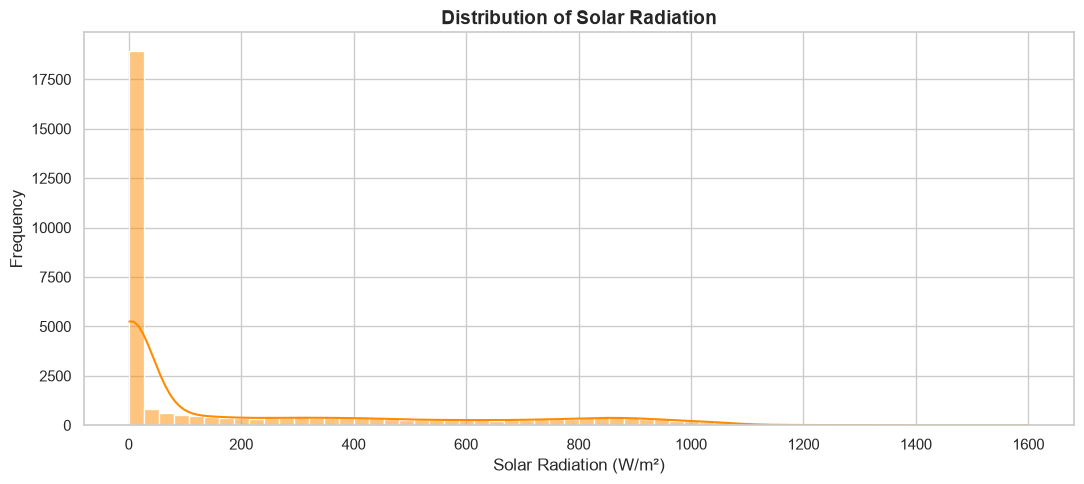

In [13]:

# Section 4.1: Solar Radiation Distribution and Variability

from pathlib import Path

# Define the figure directory once for reuse
figures_dir = Path("../figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Use the previously prepared dataset
radiation_values = df_features["Radiation"].dropna()

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    radiation_values,
    bins=60,
    kde=True,
    color="darkorange",
    edgecolor="white",
    ax=ax
)

ax.set_title(
    "Distribution of Solar Radiation",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Solar Radiation (W/m²)")
ax.set_ylabel("Frequency")

plt.tight_layout()

# Save the figure in high resolution
fig.savefig(
    figures_dir / "4_1_solar_radiation_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure
plt.show()


#### 4.1.1 Interpretation of Solar Radiation Distribution

The solar radiation histogram exhibits a strongly right-skewed distribution, characterized by a substantial concentration of observations at low radiation levels and a long tail extending toward higher values.

The high frequency of near-zero radiation measurements is consistent with nighttime conditions, although low radiation may also occur during cloudy periods and around sunrise or sunset.

The distribution demonstrates considerable variability in solar radiation intensity, reflecting changing solar and atmospheric conditions throughout the observation period.

From an energy perspective, these findings highlight the intermittent nature of solar resource availability and the importance of understanding temporal radiation patterns for renewable energy planning.

From a forecasting perspective, the dominance of low-radiation observations may influence model performance. Therefore, subsequent model evaluation should consider prediction accuracy under both low- and high-radiation conditions.

Overall, the distribution analysis establishes the variability of the prediction target and provides a foundation for investigating diurnal and longer-term radiation patterns.

### 4.2 Diurnal Solar Radiation Patterns

Solar radiation follows a daily cycle influenced by the Earth's rotation, solar position, and atmospheric conditions.

This analysis examines the average solar radiation recorded at different hours of the day to identify typical periods of low and high solar resource availability.

The findings will provide insights into daily solar radiation variability, potential peak solar resource periods, and the importance of time-of-day information for forecasting.

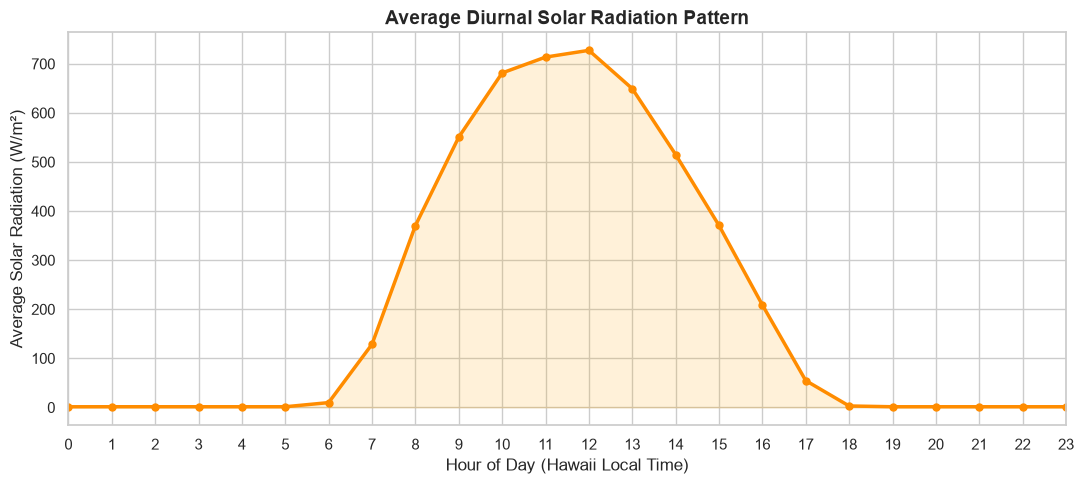

In [14]:

# Section 4.2: Diurnal Solar Radiation Patterns

# Calculate mean radiation by local hour
hourly_radiation = (
    df_features["Radiation"]
    .groupby(df_features.index.hour)
    .mean()
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    hourly_radiation.index,
    hourly_radiation.values,
    color="darkorange",
    linewidth=2.5,
    marker="o",
    markersize=5
)

ax.fill_between(
    hourly_radiation.index,
    hourly_radiation.values,
    color="orange",
    alpha=0.15
)

ax.set_title(
    "Average Diurnal Solar Radiation Pattern",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Hour of Day (Hawaii Local Time)")
ax.set_ylabel("Average Solar Radiation (W/m²)")
ax.set_xticks(range(24))
ax.set_xlim(0, 23)

plt.tight_layout()

# Save high-resolution figure
fig.savefig(
    figures_dir / "4_2_diurnal_solar_radiation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#### 4.2.1 Interpretation of Diurnal Solar Radiation Patterns

The diurnal analysis reveals a clear daily solar radiation cycle, characterized by low radiation levels during nighttime and increasing radiation intensity after sunrise.

Average solar radiation begins increasing around 6:00 AM and reaches its maximum of approximately 725 W/m² at 12:00 PM. Radiation subsequently declines throughout the afternoon, approaching zero around 6:00 PM.

The highest average radiation levels occur approximately between 9:00 AM and 3:00 PM, indicating the period of greatest solar resource availability.

These findings demonstrate the strong influence of time of day on solar radiation intensity and highlight the importance of temporal patterns in solar energy forecasting.

The observed daily cycle also supports the use of cyclical time features developed during preprocessing, which can help prediction models capture recurring variations in solar radiation.

### 4.3 Monthly Solar Radiation Variability

This section examines variations in average solar radiation across the months covered by the dataset (September–December 2016).

The objective is to identify monthly differences in solar radiation intensity, assess temporal variability, and understand their implications for solar energy availability and prediction.

Monthly averages are calculated using available observations to avoid treating missing measurements as zero radiation.

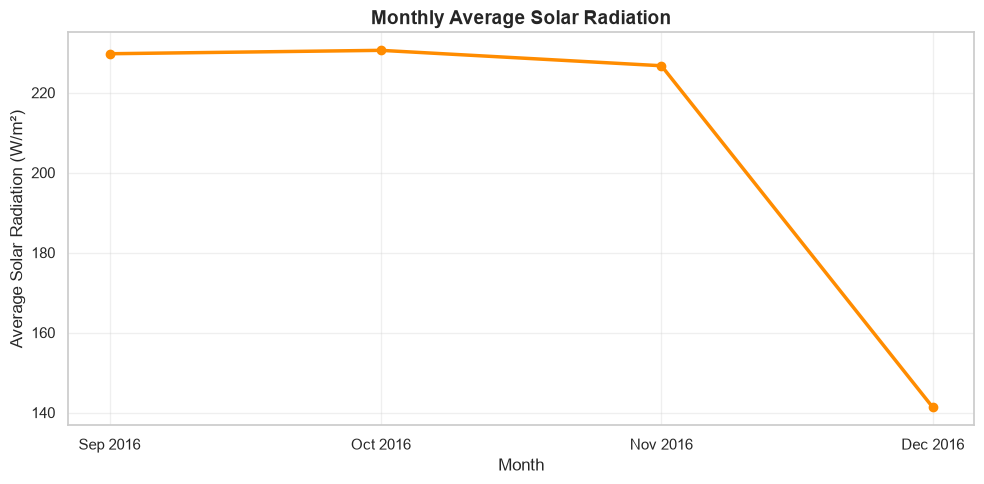

In [15]:
# Section 4.3 — Monthly Solar Radiation Variability

# Calculate monthly average solar radiation
monthly_radiation = (
    df_features["Radiation"]
    .resample("MS")
    .mean()
)

# Create the visualization
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_radiation.index,
    monthly_radiation.values,
    marker="o",
    linewidth=2.5,
    color="darkorange"
)

ax.set_title(
    "Monthly Average Solar Radiation",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Average Solar Radiation (W/m²)")

ax.set_xticks(monthly_radiation.index)
ax.set_xticklabels(
    monthly_radiation.index.strftime("%b %Y")
)

ax.grid(True, alpha=0.3)

plt.tight_layout()

# Save the figure
fig.savefig(
    "../figures/monthly_average_solar_radiation.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure
plt.show()

### Interpretation of Monthly Solar Radiation Variability

The monthly analysis reveals relatively stable average solar radiation between September and November 2016, with October recording the highest average at approximately 231 W/m².

A substantial decline is observed in December, when average radiation falls to approximately 141 W/m², representing a reduction of about 39% compared with October.

This variation suggests that solar resource availability changes across the observed months, with potential implications for solar energy generation and forecasting.

However, the monthly averages are based on available measurements, including nighttime observations. Missing data intervals and differences in monthly coverage may influence the results. Therefore, the observed pattern should not be interpreted as a definitive seasonal trend without further investigation.

### 4.4 Relationship Between Solar Radiation and Meteorological Variables

This section investigates the relationships between solar radiation and selected meteorological variables, including temperature, humidity, atmospheric pressure, and wind speed.

A correlation heatmap is used to examine the strength and direction of linear relationships between these variables.

The analysis provides preliminary insights into potential predictors of solar radiation. However, correlation does not imply causation.

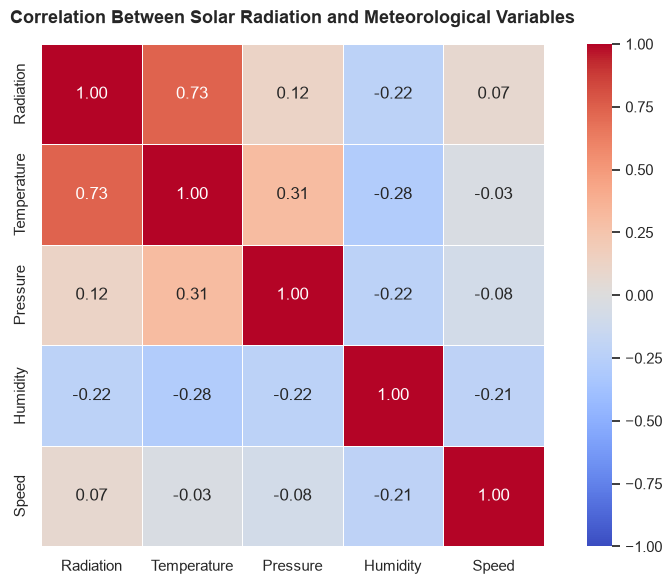

In [16]:
# Section 4.4 — Correlation Analysis

# Select existing meteorological variables
correlation_cols = [
    "Radiation",
    "Temperature",
    "Pressure",
    "Humidity",
    "Speed"
]

# Calculate the Pearson correlation matrix
correlation_matrix = df_features[correlation_cols].corr()

# Create the correlation heatmap
fig, ax = plt.subplots(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    ax=ax
)

ax.set_title(
    "Correlation Between Solar Radiation and Meteorological Variables",
    fontsize=13,
    fontweight="bold",
    pad=15
)

plt.tight_layout()

# Save the figure
fig.savefig(
    "../figures/solar_radiation_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure
plt.show()

### Interpretation of Correlation Analysis

The correlation analysis reveals varying degrees of linear association between solar radiation and the selected meteorological variables.

Temperature exhibits the strongest positive correlation with solar radiation (r = 0.73), indicating that higher temperatures generally coincide with higher solar radiation measurements.

Humidity demonstrates a weak negative correlation (r = -0.22), suggesting that increasing humidity is associated with slightly lower solar radiation levels.

Atmospheric pressure (r = 0.12) and wind speed (r = 0.07) exhibit weak and very weak positive correlations, respectively, indicating limited linear relationships with solar radiation.

**Implications for Solar Radiation Prediction**

Temperature emerges as a potentially important predictor of solar radiation. However, the remaining meteorological variables may still contribute useful information through nonlinear relationships and interactions.

These findings provide preliminary guidance for feature selection during predictive modeling. Correlation does not establish causation, and predictive importance must be evaluated using appropriate time-series validation techniques.

### 4.5 Daytime vs. Nighttime Solar Radiation Analysis

This section investigates the distribution of solar radiation during daylight and nighttime periods.

The objective is to understand how solar radiation measurements differ between these periods and assess the implications for solar radiation forecasting.

Daytime and nighttime observations are identified using the sunrise and sunset information available in the original dataset.

In [17]:
# Section 4.5 — Check available columns for day/night analysis

print("Available columns in df_features:")
print(df_features.columns.tolist())

Available columns in df_features:
['Radiation', 'Temperature', 'Pressure', 'Humidity', 'Speed', 'WindDirection(Degrees)', 'Hour_sin', 'Hour_cos', 'Day_sin', 'Day_cos', 'Wind_sin', 'Wind_cos']


In [18]:
# Section 4.5 — Locate existing sunrise and sunset data

for name in ["df", "df_clean", "df_resampled"]:
    if name in globals():
        dataset = globals()[name]

        print(f"\n{name}:")
        print([
            col for col in dataset.columns
            if "sun" in col.lower()
        ])


df:
['TimeSunRise', 'TimeSunSet']

df_clean:
['TimeSunRise', 'TimeSunSet']

df_resampled:
[]


Daytime and Nighttime Observation Counts:


Period
Nighttime    17078
Daytime      15606
Name: count, dtype: int64


Average Solar Radiation by Period (W/m²):


Period
Daytime     432.21
Nighttime     1.41
Name: Radiation, dtype: float64

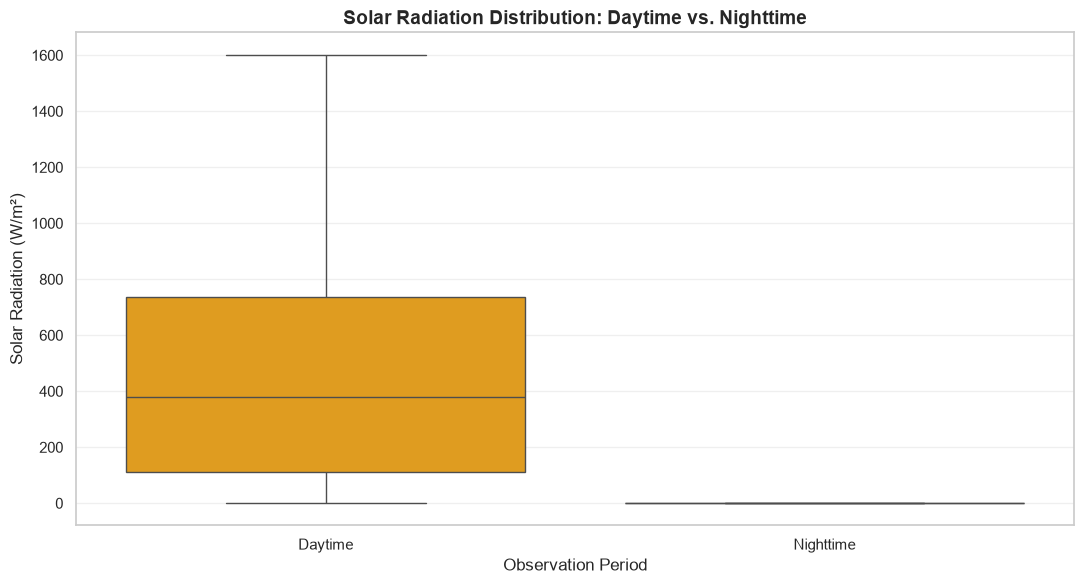

In [27]:
# Section 4.5 — Daytime vs. Nighttime Solar Radiation Analysis

# Extract solar radiation from the existing feature dataset
day_night_df = df_features[["Radiation"]].copy()

# Convert sunrise and sunset times to minutes after midnight
sunrise_minutes = (
    pd.to_timedelta(df_clean["TimeSunRise"].astype(str))
    .dt.total_seconds() / 60
)

sunset_minutes = (
    pd.to_timedelta(df_clean["TimeSunSet"].astype(str))
    .dt.total_seconds() / 60
)

# Recover observation dates from UNIX timestamps (Hawaii local time)
original_dates = (
    pd.to_datetime(df_clean["UNIXTime"], unit="s", utc=True)
    .dt.tz_convert("Pacific/Honolulu")
    .dt.date
)

# Associate sunrise and sunset with their observation dates
sun_times = pd.DataFrame({
    "Date": original_dates.to_numpy(),
    "Sunrise": sunrise_minutes.to_numpy(),
    "Sunset": sunset_minutes.to_numpy()
})

# Calculate daily sunrise and sunset times
daily_sun_times = (
    sun_times.groupby("Date")[["Sunrise", "Sunset"]]
    .median()
)

# Ensure feature timestamps use Hawaii local time
if day_night_df.index.tz is None:
    raise ValueError(
        "df_features must have a timezone-aware DatetimeIndex. "
        "Check the timestamp preprocessing in Section 3."
    )

local_index = day_night_df.index.tz_convert("Pacific/Honolulu")

# Align daily sunrise and sunset times with the feature dataset
feature_dates = pd.Index(local_index.date)

day_night_df["Sunrise"] = (
    daily_sun_times["Sunrise"]
    .reindex(feature_dates)
    .to_numpy()
)

day_night_df["Sunset"] = (
    daily_sun_times["Sunset"]
    .reindex(feature_dates)
    .to_numpy()
)

# Convert observation timestamps to minutes after midnight
observation_minutes = (
    local_index.hour * 60
    + local_index.minute
    + local_index.second / 60
)

# Classify daytime and nighttime using sunrise and sunset
daytime_mask = (
    (observation_minutes >= day_night_df["Sunrise"])
    & (observation_minutes < day_night_df["Sunset"])
)

day_night_df["Period"] = np.where(
    daytime_mask,
    "Daytime",
    "Nighttime"
)

# Exclude observations without valid radiation or sun-time data
day_night_df = day_night_df.dropna(
    subset=["Radiation", "Sunrise", "Sunset"]
)

# Display classification summary
print("Daytime and Nighttime Observation Counts:")
display(day_night_df["Period"].value_counts())

print("\nAverage Solar Radiation by Period (W/m²):")
display(
    day_night_df.groupby("Period")["Radiation"]
    .mean()
    .round(2)
)

# Create daytime versus nighttime radiation boxplot
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=day_night_df,
    x="Period",
    y="Radiation",
    order=["Daytime", "Nighttime"],
    color="orange",
    showfliers=False
)

plt.title(
    "Solar Radiation Distribution: Daytime vs. Nighttime",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Observation Period")
plt.ylabel("Solar Radiation (W/m²)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Ensure the figures directory exists
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Save the figure
plt.savefig(
    figures_dir / "daytime_vs_nighttime_radiation.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure
plt.show()

In [33]:
# Section 4.5 - Check nighttime solar radiation statistics

# Extract nighttime radiation from the existing DataFrame
nighttime_radiation = day_night_df.loc[
    day_night_df["Period"] == "Nighttime", "Radiation"
]

# Display descriptive statistics
print("Nighttime Solar Radiation Statistics:")
print(nighttime_radiation.describe())

# Check nighttime readings above 10 W/m²
print(
    "\nNighttime readings above 10 W/m²:",
    (nighttime_radiation > 10).sum()
)

# Check maximum nighttime radiation
print(
    "\nMaximum nighttime radiation (W/m²):",
    nighttime_radiation.max()
)

Nighttime Solar Radiation Statistics:
count   17078.00
mean        1.41
std         0.60
min         1.11
25%         1.21
50%         1.23
75%         1.26
max        15.75
Name: Radiation, dtype: float64

Nighttime readings above 10 W/m²: 2

Maximum nighttime radiation (W/m²): 15.75


### Interpretation of Daytime and Nighttime Solar Radiation

The analysis reveals a clear difference between daytime and nighttime solar radiation. Daytime observations recorded an average radiation intensity of 432.21 W/m², compared with only 1.41 W/m² during nighttime.

Nighttime radiation measurements remained consistently low, with a median of 1.23 W/m². Only two nighttime observations exceeded 10 W/m², while the maximum recorded value was 15.75 W/m².

The small positive nighttime measurements may indicate sensor offset or measurement noise. These values require further investigation before applying any correction.

Overall, the results confirm the strong influence of daylight availability on solar radiation and highlight the importance of considering day-night patterns when developing solar radiation prediction models.

In [34]:
# Section 4.5 - Inspect unusual nighttime radiation readings

unusual_nighttime = day_night_df.loc[
    (day_night_df["Period"] == "Nighttime") &
    (day_night_df["Radiation"] > 10)
]

print("Unusual Nighttime Solar Radiation Observations:")
display(unusual_nighttime)

Unusual Nighttime Solar Radiation Observations:


,Radiation,Sunrise,Sunset,Period
Datetime,,,,
2016-12-20 06:45:00-10:00,10.93,412.00,1068.00,Nighttime
2016-12-20 06:50:00-10:00,15.75,412.00,1068.00,Nighttime


Further investigation identified two elevated nighttime radiation readings of 10.93 W/m² and 15.75 W/m², recorded at 06:45 and 06:50 on 20 December 2016, respectively. Both observations occurred shortly before the recorded sunrise at 06:52. These measurements may be associated with dawn twilight rather than sensor errors. Consequently, the observations were retained without modification.